Obiettivo del Progetto

L'obiettivo è esplorare due metodologie distinte (DBSCAN e Elbow Method tramite Inertia/WCSS) per determinare il numero ottimale di cluster $K$ su un dataset non etichettato. Successivamente, si applicherà l'algoritmo K-Means utilizzando il valore di $K$ identificato. Per questo esercizio verrà utilizzato il dataset Iris, ignorando le etichette di classe originali.

1. Data Exploration & Preprocessing

Caricamento e Analisi: Caricare il dataset e fornire un'analisi descrittiva iniziale (es. df.describe()).Standardizzazione: Applicare la standardizzazione alle feature ($X$) per garantire che tutti gli attributi abbiano media zero e deviazione standard unitaria.

In [50]:
import numpy as np
from sklearn.cluster import DBSCAN, KMeans
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.preprocessing import StandardScaler
import pandas as pd
from sklearn.metrics import silhouette_score

In [7]:
iris = load_iris()
df = pd.DataFrame(iris.data, columns=iris.feature_names)
print(df.describe())

       sepal length (cm)  sepal width (cm)  petal length (cm)  \
count         150.000000        150.000000         150.000000   
mean            5.843333          3.057333           3.758000   
std             0.828066          0.435866           1.765298   
min             4.300000          2.000000           1.000000   
25%             5.100000          2.800000           1.600000   
50%             5.800000          3.000000           4.350000   
75%             6.400000          3.300000           5.100000   
max             7.900000          4.400000           6.900000   

       petal width (cm)  
count        150.000000  
mean           1.199333  
std            0.762238  
min            0.100000  
25%            0.300000  
50%            1.300000  
75%            1.800000  
max            2.500000  


In [23]:
X = df.values

scaler = StandardScaler()
X_std = scaler.fit_transform(X)

print("Media zero:", X_std.mean(axis=0))
print("Deviazione standard:", X_std.std(axis=0))

Media zero: [-4.73695157e-16 -7.81597009e-16 -4.26325641e-16 -4.73695157e-16]
Deviazione standard: [1. 1. 1. 1.]


2. Stima di $K$ con DBSCAN

Eseguire l'algoritmo DBSCAN iterativamente per analizzare la struttura dei dati basata sulla densità.

Parametri di Iterazione:$min\_samples = 5$$eps \in [0.35, 0.45, 0.55]$$min\_samples = 5$$eps \in [0.35, 0.45, 0.55]$Metriche da determinare per ogni esecuzione:Il numero di cluster $K$ identificati.Il numero di punti rumorosi (label -1).Il numero di cluster $K$ identificati.Il numero di punti rumorosi (label -1).Selezione: Individuare il numero di cluster $K$ più plausibile tra i risultati ottenuti.

In [34]:
eps = [0.35, 0.45, 0.55]
min_samples = 5

for e in eps:
    db = DBSCAN(eps=e, min_samples=min_samples)
    db.fit(X_std)
    clusters = db.labels_
    print(f"Numero di cluster per eps={e}:", len(set(clusters)) - (1 if -1 in clusters else 0))

Numero di cluster per eps=0.35: 4
Numero di cluster per eps=0.45: 3
Numero di cluster per eps=0.55: 2


3. Stima di $K$ con Elbow Method

Utilizzare K-Means per identificare il $K$ ottimale analizzando l'inerzia (o WCSS: Within Cluster Sum of Squares).

Configurazione:Algoritmo: K-Means.Range di $K$: da 1 a 10.Algoritmo: K-Means.Range di $K$: da 1 a 10.Visualizzazione:Plot del grafico dell'Elbow Method (Inerzia sull'asse Y e $K$ sull'asse X).Identificazione del "punto di gomito" (dove la curva si piega).Inserimento di un asse verticale in corrispondenza del valore $x = K$ scelto.Plot del grafico dell'Elbow Method (Inerzia sull'asse Y e $K$ sull'asse X).Identificazione del "punto di gomito" (dove la curva si piega).Inserimento di un asse verticale in corrispondenza del valore $x = K$ scelto.

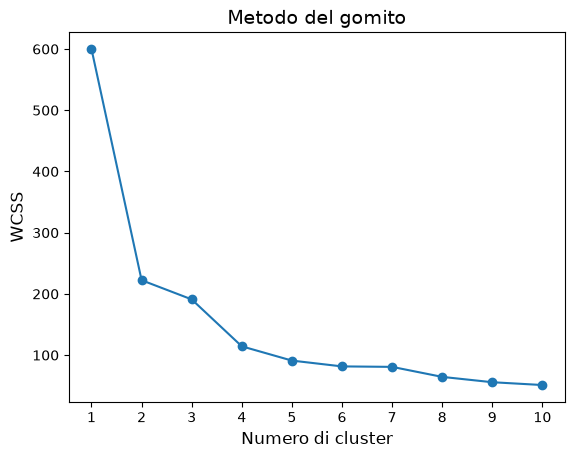

In [47]:
wcss = []

for i in range(1, 11):
    kmeans = KMeans(n_clusters=i, random_state=42)
    kmeans.fit(X_std)
    wcss.append(kmeans.inertia_)

plt.plot(range(1, 11), wcss, marker='o')
plt.xlabel('Numero di cluster', fontsize=12)
plt.xticks(range(1, 11), fontsize=10)
plt.ylabel('WCSS', fontsize=12)
plt.title('Metodo del gomito', fontsize=14)
plt.show()

4. Applicazione Finale & Visualizzazione

Clusterizzazione Definitiva: Stabilire il $K$ finale e applicare il K-Means sul dataset standardizzato.Valutazione: Calcolare il Silhouette Score per valutare la coesione interna e la separazione dei cluster.Visualizzazione Risultati:Plot dei dati proiettati in 2D (utilizzando le prime due feature).+1Rappresentazione dei centroidi dei cluster.Plot dei dati proiettati in 2D (utilizzando le prime due feature).+1Rappresentazione dei centroidi dei cluster.

Silhouette Score: 0.4798814508199818


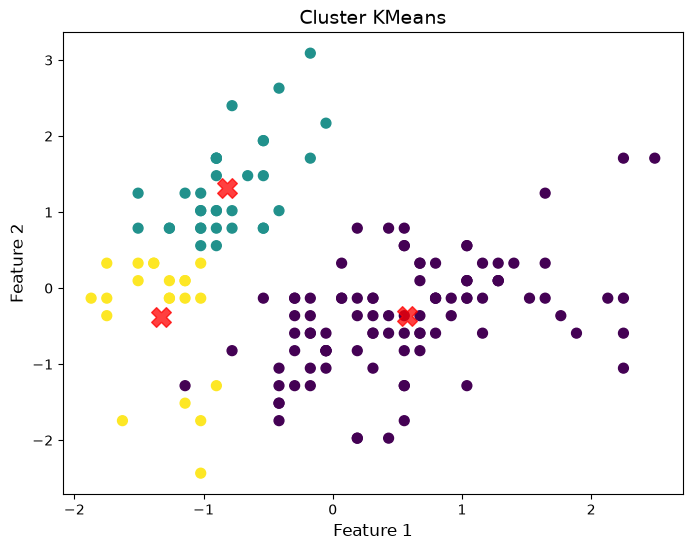

In [55]:
km = KMeans(n_clusters=3, random_state=42)
km.fit(X_std)
labels = km.labels_

sil_score = silhouette_score(X_std, labels)
print("Silhouette Score:", sil_score)

centers = km.cluster_centers_

plt.figure(figsize=(8, 6))
plt.scatter(X_std[:, 0], X_std[:, 1], c=labels, cmap='viridis', s=50)
plt.scatter(centers[:, 0], centers[:, 1], c='red', s=200, alpha=0.75, marker='X')
plt.title('Cluster KMeans', fontsize=14)
plt.xlabel('Feature 1', fontsize=12)
plt.ylabel('Feature 2', fontsize=12)
plt.show()